# Customer Segmentation and Prediction (Python)
**Objective:** segment customers by purchasing behaviour (K-Means on RFM) and predict future buying patterns.

**Dataset:** `online_retail.csv` (InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country)

**Steps:** 1) Load → 2) Clean → 3) Time split → 4) Feature engineering → 5) K-Means segmentation → 6) Prediction models → 7) Evaluation → 8) Insights & marketing strategy

## 1. Import libraries and load data

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, accuracy_score, precision_score, recall_score,
                             mean_squared_error, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
%matplotlib inline

In [ ]:
df = pd.read_csv("online_retail.csv", encoding="latin1")
print(df.shape)
df.head()

(99999, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12-01-2010,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12-01-2010,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12-01-2010,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12-01-2010,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12-01-2010,3.39,17850.0,United Kingdom


In [ ]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 99999 entries, 0 to 99998
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    99999 non-null  str    
 1   StockCode    99999 non-null  str    
 2   Description  99700 non-null  str    
 3   Quantity     99999 non-null  int64  
 4   InvoiceDate  99999 non-null  str    
 5   UnitPrice    99999 non-null  float64
 6   CustomerID   65084 non-null  float64
 7   Country      99999 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 6.1 MB

Missing values:
 InvoiceNo          0
StockCode          0
Description      299
Quantity           0
InvoiceDate        0
UnitPrice          0
CustomerID     34915
Country            0
dtype: int64

Duplicate rows: 924


,Quantity,UnitPrice,CustomerID
count,99999.000000,99999.000000,65084.000000
mean,8.892949,5.396653,15350.988415
std,336.564383,120.891603,1769.766795
min,-74215.000000,0.000000,12346.000000
25%,1.000000,1.250000,13869.000000
50%,3.000000,2.510000,15311.000000
75%,8.000000,4.250000,16997.000000
max,74215.000000,16888.020000,18283.000000


## 2. Data cleaning
- Remove exact duplicates
- Remove rows with no `CustomerID` (cannot be segmented)
- Remove cancelled invoices (InvoiceNo starts with `C`) and rows with `Quantity <= 0` or `UnitPrice <= 0`
- Fix `InvoiceDate` — the file mixes two formats (`12-01-2010` and `2/17/2011 12:42`), so we parse with `format="mixed"`
- Create `TotalPrice = Quantity × UnitPrice`

In [ ]:
df = df.drop_duplicates()
df = df.dropna(subset=["CustomerID"])
df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df = df[~df["InvoiceNo"].str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["Description"] = df["Description"].fillna("UNKNOWN").str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="mixed", dayfirst=False)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("Clean shape:", df.shape)
print("Date range :", df["InvoiceDate"].min(), "→", df["InvoiceDate"].max())
print("Customers  :", df["CustomerID"].nunique())

Clean shape: (62408, 9)
Date range : 2010-12-01 00:00:00 → 2011-02-23 13:21:00
Customers  : 1596


## 3. Split into history and "future"
To predict *future* purchases without data leakage, features are built only from data **before** a cutoff date; the target comes from the **last 30 days**.

In [ ]:
cutoff = df["InvoiceDate"].max() - pd.Timedelta(days=30)
snapshot = cutoff + pd.Timedelta(days=1)
hist = df[df["InvoiceDate"] <= cutoff]
future = df[df["InvoiceDate"] > cutoff]
print("Cutoff:", cutoff, "| history rows:", len(hist), "| future rows:", len(future))

Cutoff: 2011-01-24 13:21:00 | history rows: 40512 | future rows: 21896


## 4. Feature engineering (one row per customer)
| Feature | Meaning |
|---|---|
| Recency | days since last purchase |
| Frequency | number of distinct invoices |
| Monetary | total spend = historical customer lifetime value |
| AOV | average order value = Monetary / Frequency |
| UniqueProducts | distinct products bought |
| AvgItemsPerOrder | items per invoice |
| Tenure | days since first purchase |

In [ ]:
feat = hist.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    TotalItems=("Quantity", "sum"),
    FirstPurchase=("InvoiceDate", "min"),
    Country=("Country", "first"),
)
feat["AOV"] = feat["Monetary"] / feat["Frequency"]
feat["Tenure"] = (snapshot - feat["FirstPurchase"]).dt.days
feat["AvgItemsPerOrder"] = feat["TotalItems"] / feat["Frequency"]
feat = feat.drop(columns=["FirstPurchase", "TotalItems"])
feat.describe().round(1)

,Recency,Frequency,Monetary,UniqueProducts,AOV,Tenure,AvgItemsPerOrder
count,1178.0,1178.0,1178.0,1178.0,1178.0,1178.0,1178.0
mean,29.4,1.8,870.6,30.5,473.1,38.6,290.4
std,18.1,2.1,3036.4,35.3,2329.5,16.5,2186.6
min,1.0,1.0,0.8,1.0,0.8,1.0,1.0
25%,13.0,1.0,205.7,10.0,170.3,32.2,75.0
50%,36.0,1.0,353.6,20.0,290.7,46.0,131.5
75%,47.0,2.0,709.8,39.0,413.8,51.0,247.8
max,55.0,39.0,77183.6,511.0,77183.6,55.0,74215.0


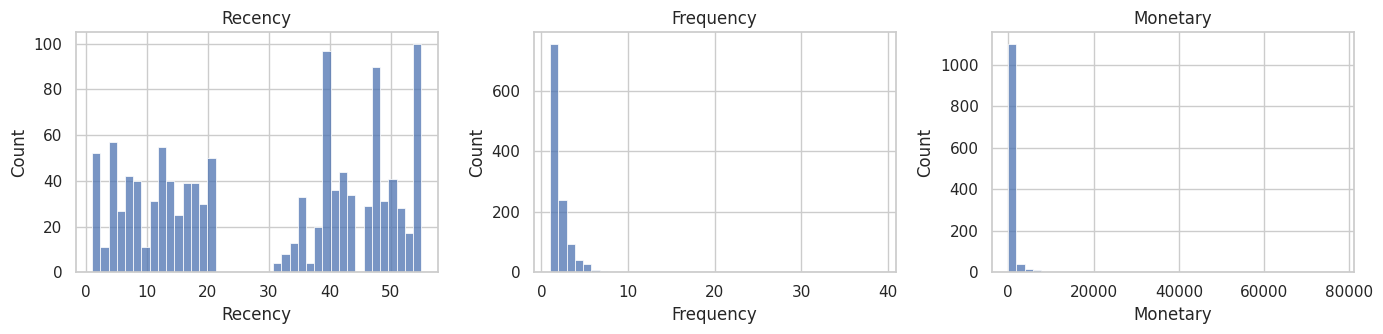

In [ ]:
# Distributions are heavily right-skewed -> we will use a log transform before clustering
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, c in zip(ax, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(feat[c], bins=40, ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

## 5. Customer segmentation with K-Means

**5.1 Scale the features** — `log1p` reduces skew, `StandardScaler` puts R, F, M on the same scale.

In [ ]:
rfm = feat[["Recency", "Frequency", "Monetary"]]
rfm_scaled = StandardScaler().fit_transform(np.log1p(rfm))

**5.2 Choose the number of clusters (k)** using the elbow method and silhouette score.

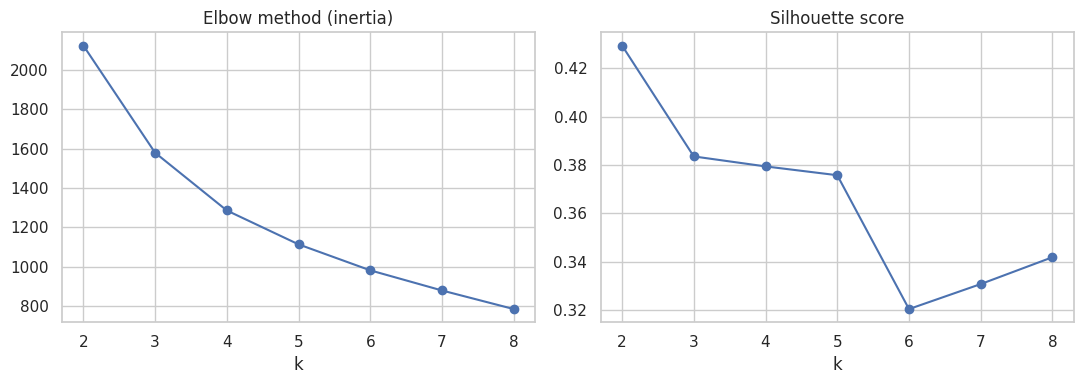

In [ ]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(rfm_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(rfm_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, "o-");     ax[1].set_title("Silhouette score");       ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

**5.3 Fit the final model.** k = 4 gives clearly interpretable business groups (try 3–5 and compare).

In [ ]:
K = 4
feat["Cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(rfm_scaled)

profile = feat.groupby("Cluster").agg(
    Customers=("Monetary", "size"), Recency=("Recency", "mean"), Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"), AOV=("AOV", "mean")).round(1)
profile

,Customers,Recency,Frequency,Monetary,AOV
Cluster,,,,,
0,109,10.3,5.6,4572.3,1549.5
1,548,43.1,1.0,262.1,257.6
2,266,8.2,1.3,456.2,383.4
3,255,30.2,2.2,1028.2,569.6


**5.4 Name the segments** from their profile (ranked by average spend).

In [ ]:
order = profile.sort_values("Monetary", ascending=False).index.tolist()
names = ["Champions (high value)", "Loyal / frequent", "Potential / new", "At-risk / low value"]
feat["Segment"] = feat["Cluster"].map({c: names[i] for i, c in enumerate(order)})

# Check the names make sense against the profile above — rename here if your run differs!
profile.loc[order].assign(Segment=names)

,Customers,Recency,Frequency,Monetary,AOV,Segment
Cluster,,,,,,
0,109,10.3,5.6,4572.3,1549.5,Champions (high value)
3,255,30.2,2.2,1028.2,569.6,Loyal / frequent
2,266,8.2,1.3,456.2,383.4,Potential / new
1,548,43.1,1.0,262.1,257.6,At-risk / low value


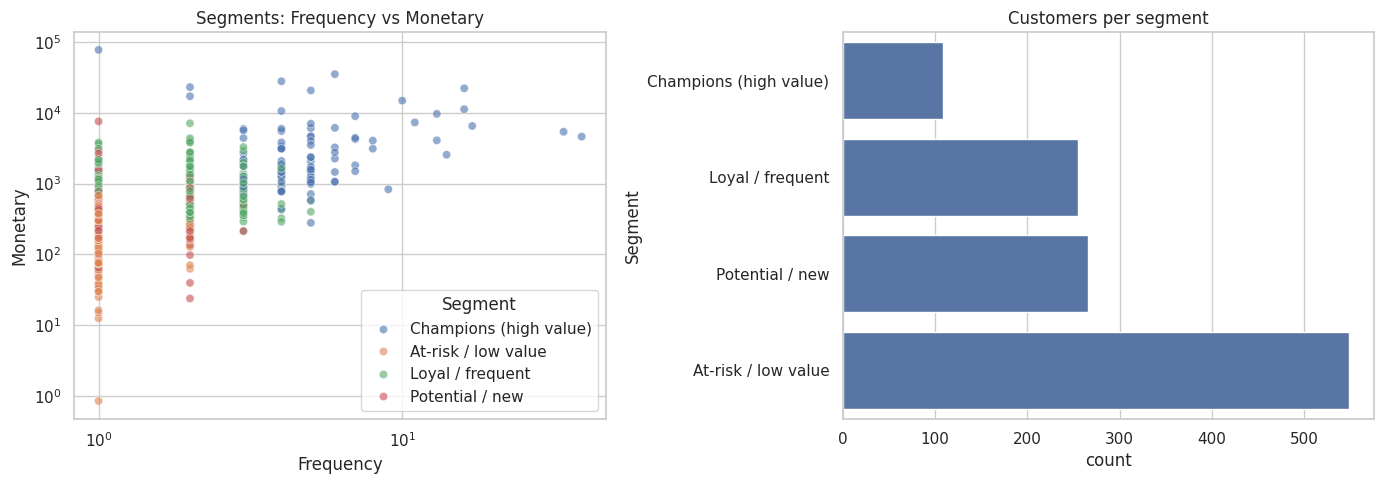

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=feat, x="Frequency", y="Monetary", hue="Segment", alpha=.6, ax=ax[0])
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_title("Segments: Frequency vs Monetary")
sns.countplot(data=feat, y="Segment", order=names, ax=ax[1]); ax[1].set_title("Customers per segment")
plt.tight_layout(); plt.show()

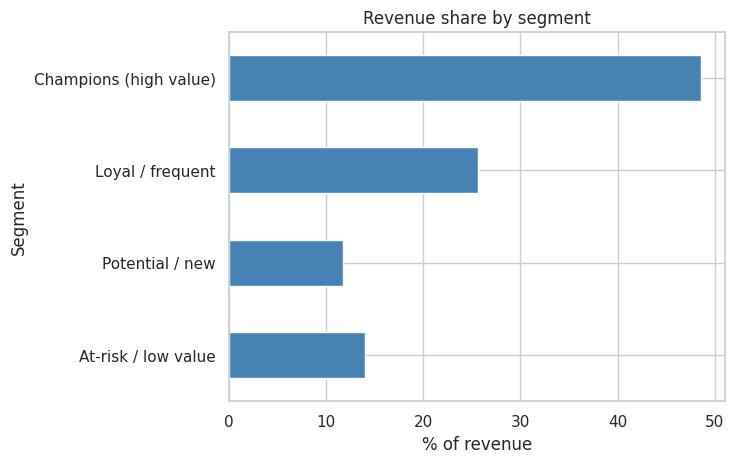

In [ ]:
# Share of revenue by segment
rev = feat.groupby("Segment")["Monetary"].sum().reindex(names)
(rev / rev.sum() * 100).round(1).plot.barh(color="steelblue").invert_yaxis()
plt.xlabel("% of revenue"); plt.title("Revenue share by segment"); plt.show()

## 6. Predicting future purchases
Targets come from the 30-day future window:
- `WillBuy` — will the customer buy again? (**classification**)
- `FutureSpend` — how much will they spend? (**regression**)

In [ ]:
fut = future.groupby("CustomerID").agg(FutureSpend=("TotalPrice", "sum"))
data = feat.join(fut).fillna({"FutureSpend": 0})
data["WillBuy"] = (data["FutureSpend"] > 0).astype(int)

print(data["WillBuy"].value_counts(normalize=True).round(2))
features = ["Recency", "Frequency", "Monetary", "AOV", "UniqueProducts",
            "AvgItemsPerOrder", "Tenure", "Cluster"]
X = data[features]

WillBuy
0    0.66
1    0.34
Name: proportion, dtype: float64


### 6.1 Classification — Decision Tree (will the customer buy again?)

Accuracy : 0.722
Precision: 0.58
Recall   : 0.683


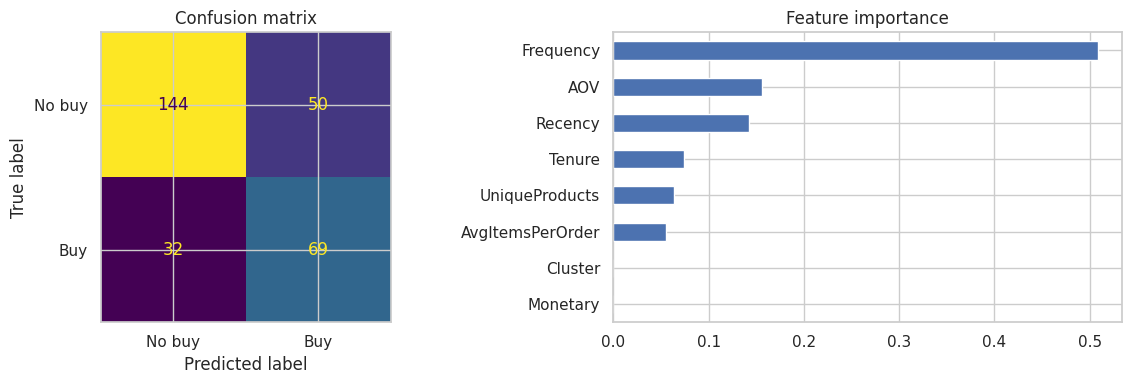

In [ ]:
Xtr, Xte, ytr, yte = train_test_split(X, data["WillBuy"], test_size=.25,
                                      random_state=42, stratify=data["WillBuy"])
clf = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42).fit(Xtr, ytr)
pred = clf.predict(Xte)

print("Accuracy :", round(accuracy_score(yte, pred), 3))
print("Precision:", round(precision_score(yte, pred), 3))
print("Recall   :", round(recall_score(yte, pred), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["No buy", "Buy"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix")
pd.Series(clf.feature_importances_, features).sort_values().plot.barh(ax=ax[1], title="Feature importance")
plt.tight_layout(); plt.show()

### 6.2 Regression — Random Forest (how much will they spend?)
Spend is very skewed (a few huge buyers), so we model `log(1 + spend)`; RMSE is therefore on the log scale.

In [ ]:
y = np.log1p(data["FutureSpend"])
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=42)
reg = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42).fit(Xtr, ytr)

rmse = np.sqrt(mean_squared_error(yte, reg.predict(Xte)))
base = np.sqrt(mean_squared_error(yte, np.full(len(yte), ytr.mean())))
print(f"RMSE (log scale): {rmse:.3f}   |   baseline (always predict the mean): {base:.3f}")

RMSE (log scale): 2.665   |   baseline (always predict the mean): 2.906


## 8. Insights per segment

In [ ]:
summary = data.groupby("Segment").agg(
    Customers=("WillBuy", "size"),
    AvgRecency=("Recency", "mean"), AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"), AvgAOV=("AOV", "mean"),
    RepeatRate=("WillBuy", "mean"), AvgFutureSpend=("FutureSpend", "mean")
).round(2).reindex(names)
summary

,Customers,AvgRecency,AvgFrequency,AvgMonetary,AvgAOV,RepeatRate,AvgFutureSpend
Segment,,,,,,,
Champions (high value),109,10.33,5.63,4572.28,1549.50,0.72,1262.08
Loyal / frequent,255,30.21,2.19,1028.25,569.62,0.50,386.51
Potential / new,266,8.21,1.30,456.19,383.39,0.30,118.45
At-risk / low value,548,43.12,1.04,262.11,257.64,0.21,78.20


### Recommended marketing strategy
| Segment | Behaviour | Action |
|---|---|---|
| **Champions (high value)** | Recent, frequent, highest spend, highest repeat rate | VIP / early-access programme, exclusive products, referral rewards — protect, don't over-discount |
| **Loyal / frequent** | Regular buyers, mid spend | Loyalty points, bundles and cross-sell to raise order value |
| **Potential / new** | Bought recently but only once or twice | Welcome series, second-purchase coupon, product recommendations |
| **At-risk / low value** | Long since last purchase, one order, low spend | Win-back emails with a time-limited offer; low-cost channels only |

